<a href="https://colab.research.google.com/github/uranovnass/task/blob/main/ml11_A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys
import time
import sklearn
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold

print(
    "Python", sys.version.split()[0],
    "| sklearn", sklearn.__version__,
    "| numpy", np.__version__,
    "| pandas", pd.__version__,
    "| matplotlib", matplotlib.__version__
)

Python 3.13.18 | sklearn 1.6.1 | numpy 2.4.6 | pandas 2.2.3 | matplotlib 3.10.0


In [ ]:
plt.rcParams.update({"font.family": "sans-serif", "font.size": 12,
                     "font.sans-serif": ["IBM Plex Sans", "DejaVu Sans", "Arial"],
                     "figure.facecolor": "#F5F4EF", "axes.facecolor": "#F5F4EF",
                     "savefig.facecolor": "#F5F4EF", "axes.spines.top": False,
                     "axes.spines.right": False})
COLORS = np.array(["#A84C14", "#2A5DB0", "#3F8F6B", "#7A5BA6"])
import os; os.makedirs("figs", exist_ok=True)

In [ ]:
data = load_breast_cancer()
X, y = data.data, data.target          # y: 0 — злокачественная, 1 — доброкачественная
print(X.shape, "| классы:", np.bincount(y).tolist())
X_scaled = StandardScaler().fit_transform(X)
pca = PCA().fit(X_scaled)
print(np.round(pca.explained_variance_ratio_[:6], 3))

(569, 30) | классы: [212, 357]
[0.443 0.19  0.094 0.066 0.055 0.04 ]


Первые 2 компоненты: 0.632


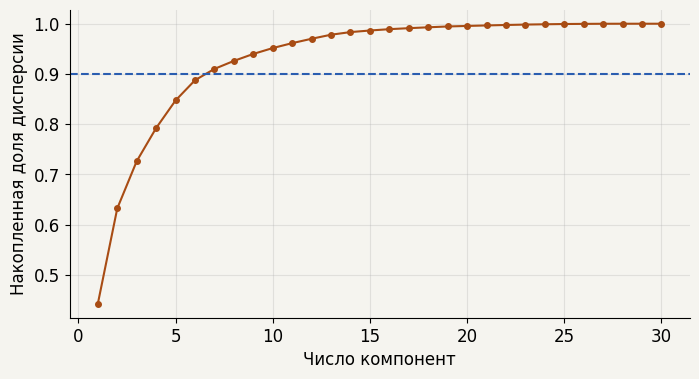

In [ ]:
cum = np.cumsum(pca.explained_variance_ratio_)
print("Первые 2 компоненты:", round(cum[1], 3))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, 31), cum, "o-", color="#A84C14", ms=4)
ax.axhline(0.90, ls="--", color="#2A5DB0")
ax.set_xlabel("Число компонент"); ax.set_ylabel("Накопленная доля дисперсии")
ax.grid(alpha=0.3)
plt.show()

In [ ]:
n90 = np.argmax(cum >= 0.90) + 1

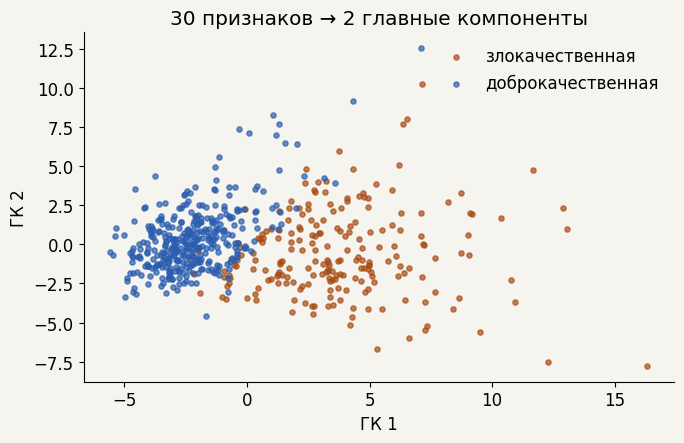

In [ ]:
Z = PCA(n_components=2).fit_transform(X_scaled)
fig, ax = plt.subplots(figsize=(7, 4.6))
for c, name in [(0, "злокачественная"), (1, "доброкачественная")]:
    ax.scatter(Z[y == c, 0], Z[y == c, 1], s=14, alpha=0.7, c=COLORS[c], label=name)
ax.set_xlabel("ГК 1"); ax.set_ylabel("ГК 2"); ax.legend(frameon=False)
ax.set_title("30 признаков → 2 главные компоненты")
fig.tight_layout(); fig.savefig("figs/pr11_pca2d.png", dpi=160)
plt.show()

In [ ]:
from sklearn.cluster import KMeans
cust = pd.read_csv("/content/sample_data/customers.csv")
features = ["avg_check", "purchases_month", "days_since_last", "discount_share"]
Xc = StandardScaler().fit_transform(cust[features])
clusters = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(Xc)
pca_c = PCA(n_components=2).fit(Xc)
Zc = pca_c.transform(Xc)
print("Доля дисперсии двух ГК:", np.round(pca_c.explained_variance_ratio_, 3),
      "| сумма:", round(pca_c.explained_variance_ratio_.sum(), 3))
print(pd.DataFrame(pca_c.components_, columns=features, index=["ГК 1", "ГК 2"]).round(2))

Доля дисперсии двух ГК: [0.571 0.351] | сумма: 0.922
      avg_check  purchases_month  days_since_last  discount_share
ГК 1      -0.46             0.57            -0.37            0.58
ГК 2      -0.58            -0.34             0.67            0.31


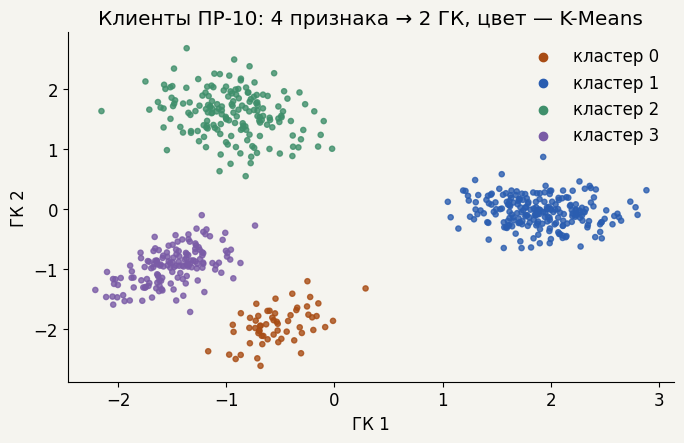

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4.6))

ax.scatter(
    Zc[:, 0],
    Zc[:, 1],
    c=COLORS[clusters],
    s=14,
    alpha=0.8
)

for c in range(4):
    ax.scatter(
        [],
        [],
        c=COLORS[c],
        label=f"кластер {c}"
    )

ax.set_xlabel("ГК 1")
ax.set_ylabel("ГК 2")
ax.legend(frameon=False)
ax.set_title("Клиенты ПР-10: 4 признака → 2 ГК, цвет — K-Means")

fig.tight_layout()
fig.savefig("figs/pr11_customers_pca.png", dpi=160)

plt.show()

ГК 1: 57.1% дисперсии
ГК 2: 35.1%
вместе: 92.2%

| Признак | ГК 1 | ГК 2 |
|---|---:|---:|
| avg_check | -0.46 | -0.58 |
| purchases_month | 0.57 | -0.34 |
| days_since_last | -0.37 | 0.67 |
| discount_share | 0.58 | 0.31 |

PCA здесь очень хорошо подходит для визуализации, потому что всего 2 компоненты сохраняют 92.2% информации из 4 исходных признаков.

Что видно на картинке: четыре группы клиентов хорошо разделяются на плоскости двух главных компонент. Кластеры образуют отдельные компактные области и практически не пересекаются. Поэтому двумерное представление хорошо отражает структуру сегментов клиентов.

## Уровень A

### Breast Cancer

Датасет содержит 569 объектов и 30 признаков. После масштабирования признаков методом StandardScaler был применён PCA.

Доля дисперсии первых 6 компонент:

```text
[0.443 0.190 0.094 0.066 0.055 0.040]
```

Первые две главные компоненты объясняют 63.2% общей дисперсии. Для сохранения 90% дисперсии необходимо 7 компонент.

На двумерном графике по первым двум главным компонентам классы злокачественных и доброкачественных опухолей разделяются достаточно заметно, однако полное разделение не достигается. Поэтому двухмерная визуализация полезна для общего представления структуры данных, но не сохраняет всю информацию исходных 30 признаков.

### Клиенты ПР-10

Для клиентов были использованы четыре признака: `avg_check`, `purchases_month`, `days_since_last`, `discount_share`. После масштабирования был применён PCA с двумя компонентами.

Доля дисперсии:

```text
ГК 1 = 0.571
ГК 2 = 0.351
Суммарно = 0.922
```

Таким образом, две главные компоненты сохраняют 92.2% дисперсии исходных данных.

Нагрузки компонент:

| Признак | ГК 1 | ГК 2 |
|---|---:|---:|
| avg_check | -0.46 | -0.58 |
| purchases_month | 0.57 | -0.34 |
| days_since_last | -0.37 | 0.67 |
| discount_share | 0.58 | 0.31 |

На графике четыре группы клиентов хорошо разделяются на плоскости двух главных компонент. Кластеры образуют отдельные компактные области и практически не пересекаются.

### Ответы на вопросы

**1. Сколько компонент нужно для 90% дисперсии?**

Для данных Breast Cancer необходимо 7 главных компонент.

**2. Какую долю дисперсии сохраняют две первые компоненты? Информативна ли двумерная картинка?**

Первые две компоненты сохраняют 63.2% дисперсии. Двумерная визуализация достаточно информативна для общего представления структуры данных, однако часть информации теряется.

**3. Видны ли на плоскости 4 группы клиентов из ПР-10?**

Да. Четыре группы клиентов хорошо видны и достаточно чётко разделяются на плоскости двух главных компонент.

**4. Оправдан ли PCA на этих данных? Что вы выигрываете и что теряете?**

PCA оправдан, особенно для визуализации и уменьшения размерности. Для клиентов две компоненты сохраняют 92.2% дисперсии, поэтому можно значительно упростить представление данных. Выигрыш заключается в уменьшении количества признаков и удобной визуализации. Потеря состоит в том, что главные компоненты являются комбинациями исходных признаков и хуже интерпретируются напрямую. Для Breast Cancer при переходе к двум компонентам теряется значительная часть информации.